# Speech Emotion Router (SER): Non-Linear Tabular Modeling & Performance Ceilings

In the previous phase ([`02_baseline_modeling.ipynb`](./02_baseline_modeling.ipynb)), our flat multinomial Logistic Regression benchmark established that static MFCC summaries provide strong demographic separation but struggle significantly with intra-gender emotional ambiguity.

This phase investigates whether non-linear decision boundaries can resolve overlapping affective clusters before we transition to continuous 2D spectral representations.

**Phase Objectives & Experimental Scope:**

* **Non-Linear Tabular Benchmark:** Evaluate a couple non-linear classificaiton models to try and capture the emotional relationships 
  *  For example: Support Vector Classifier with a Radial Basis Function (RBF) kernel on the 26-dimensional static MFCC summary matrix to test the limits of non-linear geometric boundaries.

* **Hyperparameter Calibration:** Conduct a structured grid search across regularization ($C$) and kernel bandwidth ($\gamma$) to balance boundary flexibility against speaker overfitting.

* **Leak-Free Grouped Validation:** Enforce the established 5-fold `StratifiedGroupKFold` harness grouped by `actor_id` with in-pipeline scaling to ensure evaluation on unseen speakers.

* **Performance Ceiling Assessment:** Compare out-of-fold metrics and confusion patterns directly against the linear baseline to determine whether static temporal summaries inherently constrain valence recognition.

In [33]:
# Standard library
from pathlib import Path
import pprint
from typing import Any, cast

# Data handling and numerical arrays
import joblib
import numpy as np
import pandas as pd

# Interactive audio display & progress tracking
from IPython.display import Audio, display
from tqdm.auto import tqdm

# Visualization
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer
import seaborn as sns

# Scikit-learn: pipelines and preprocessing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Scikit-learn: validation and evaluation metrics
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    ParameterGrid,
    StratifiedGroupKFold,
    cross_val_predict,
    cross_validate,
)

# Scikit-learn: estimators
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Plotting style configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 100

In [34]:
# Define paths and import the processed feature dataset
project_root = Path.cwd().resolve().parent
data_processed_path = project_root / "data" / "processed"

In [35]:
SEED = 36

## Prep - Load and Setup Data for Models

In [36]:
x_path = data_processed_path / "02_1_X_full.parquet"
y_path = data_processed_path / "02_1_Y_full.parquet"
groups_path = data_processed_path / "02_1_groups_full.parquet"

# Audit saved artifacts using .info()
print("--- X Artifact ---")
X = pd.read_parquet(x_path)
X.info()  # Expected: (1440, 26)

print("\n--- y Artifact ---")
y = pd.read_parquet(y_path)
y.info()  # Expected: (1440, 1) gender_emotion

print("\n--- Groups Artifact ---")
groups = pd.read_parquet(groups_path)
groups.info()  # Expected: (1440, 1) actor_id

--- X Artifact ---
<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mfcc_mean_0   1440 non-null   float64
 1   mfcc_std_0    1440 non-null   float64
 2   mfcc_mean_1   1440 non-null   float64
 3   mfcc_std_1    1440 non-null   float64
 4   mfcc_mean_2   1440 non-null   float64
 5   mfcc_std_2    1440 non-null   float64
 6   mfcc_mean_3   1440 non-null   float64
 7   mfcc_std_3    1440 non-null   float64
 8   mfcc_mean_4   1440 non-null   float64
 9   mfcc_std_4    1440 non-null   float64
 10  mfcc_mean_5   1440 non-null   float64
 11  mfcc_std_5    1440 non-null   float64
 12  mfcc_mean_6   1440 non-null   float64
 13  mfcc_std_6    1440 non-null   float64
 14  mfcc_mean_7   1440 non-null   float64
 15  mfcc_std_7    1440 non-null   float64
 16  mfcc_mean_8   1440 non-null   float64
 17  mfcc_std_8    1440 non-null   float64
 18  mfcc_mean_9   1440 n

In [37]:
# Extract target and group vectors as 1D arrays/Series
y_vec = y["gender_emotion"]
groups_vec = groups["actor_id"]

# Instantiate the speaker-independent 5-fold cross-validation harness
kfold_cv = StratifiedGroupKFold(n_splits=5)
kfold_cv

StratifiedGroupKFold(n_splits=5, random_state=None, shuffle=False)

We are now back as we started with the baseline models with:

- `X` containing the MFCC continuous variables only
- `y` containing the mixed target varible `gender_emotion`
- `groups` containing the `actor_id` used for performing the K-Fold CV
- `kfold_cv` the `StratifiedGroupKFold` 5-fold for our models. Note again, not using `shuffle` as we want to deterministically assign actors across folds so there is not data leakage

## SVC Model

### Establishing the Non-Linear Ceiling

In [`02_baseline_modeling.ipynb`](./02_baseline_modeling.ipynb), our regularized Logistic Regression baseline demonstrated that static MFCC summary statistics provide sufficient linear separability for binary speaker gender (~94.5%), but collapse when separating intra-gender emotions sharing identical arousal levels (>55% error).

Before abandoning tabular acoustic features in favor of deep convolutional architectures, we must determine whether this performance bottleneck is caused by the **rigidity of linear hyperplanes** or **an inherent information ceiling of static temporal pooling**.

**Why Support Vector Machines with an RBF Kernel?**

* By projecting the 26-dimensional feature space into an infinite-dimensional Hilbert space via the Radial Basis Function kernel ($K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \Vert{}\mathbf{x} - \mathbf{x}'\Vert{}^2)$), an RBF SVC can construct complex, ## Establishing the Non-Linear Tabular Ceiling: Support Vector Classifier (RBF)

In [`02_baseline_modeling.ipynb`](./02_baseline_modeling.ipynb), our regularized Logistic Regression baseline demonstrated that static MFCC summary statistics provide sufficient linear separability for binary speaker gender (~94.5%), but collapse when separating intra-gender emotions sharing identical arousal levels (>55% error).

Before abandoning tabular acoustic features in favor of deep convolutional architectures, we must determine whether this performance bottleneck is caused by the rigidity of linear hyperplanes or an inherent information ceiling of static temporal pooling.

**Why Support Vector Machines with an RBF Kernel?**

* **Non-Linear Geometric Warping:** By projecting the 26-dimensional feature space into an infinite-dimensional Hilbert space via the Radial Basis Function kernel ($K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \Vert{}\mathbf{x} - \mathbf{x}'\Vert{}^2)$), an RBF SVC can construct complex, curved decision boundaries capable of wrapping around overlapping affective clusters that linear boundaries slice through.

* **Robustness in Compact Feature Regimes:** With only 1,440 total trials across 16 target classes, highly parameterized models risk severe overfitting. SVMs rely exclusively on critical boundary instances (support vectors) and margin maximization rather than learning global probability distributions, making them exceptionally stable in moderate-dimensional spaces ($p=26, n=1,440$).

* **Defining the Static Feature Ceiling:** If an optimized RBF SVC fails to resolve intra-gender valence confusion, it provides empirical proof that static mean and variance summaries lack the temporal inflection contours required for affective classification—directly justifying our transition to 2D continuous spectrogram representations.decision boundaries capable of wrapping around overlapping affective clusters that linear boundaries slice through.

In [38]:
# Build leak-free RBF SVC pipeline
pipe_rbf = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", random_state=SEED)),
    ]
)

In [39]:
# Evaluate default RBF SVC using cross_validate across existing speaker groups
cv_results_default = cross_validate(  # fit
    pipe_rbf,
    X,
    y_vec,
    groups=groups_vec,
    cv=kfold_cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1,
    return_train_score=True,
)

In [40]:
# Compute out-of-fold predictions for baseline comparison
y_pred_oof_default = cross_val_predict(
    pipe_rbf,
    X,
    y_vec,
    groups=groups_vec,
    cv=kfold_cv,
    n_jobs=-1,
)

In [41]:
# Display default model baseline summary
mean_train_acc = np.mean(cv_results_default["train_accuracy"])
mean_val_acc = np.mean(cv_results_default["test_accuracy"])
mean_val_f1 = np.mean(cv_results_default["test_f1_macro"])
mean_fit_time = np.mean(cv_results_default["fit_time"])
total_fit_time = np.sum(cv_results_default["fit_time"])

print("--- Default RBF SVC (C=1.0, gamma='scale') Results ---")
print(f"Mean Train Accuracy: {mean_train_acc:.4f}")
print(f"Mean Out-of-Fold Val Accuracy: {mean_val_acc:.4f}")
print(f"Mean Out-of-Fold Val Macro F1: {mean_val_f1:.4f}")
print(f"Mean Fit Time per Fold: {mean_fit_time:.4f}s (Total: {total_fit_time:.4f}s)")

--- Default RBF SVC (C=1.0, gamma='scale') Results ---
Mean Train Accuracy: 0.8583
Mean Out-of-Fold Val Accuracy: 0.4060
Mean Out-of-Fold Val Macro F1: 0.3619
Mean Fit Time per Fold: 0.0403s (Total: 0.2016s)


### SVC Performance - Observations

- The RBF kernel improved validation accuracy by `+1.93%` over the flat Logistic Regression benchmark (`38.67%` to `40.60%`), a modest amount. Clearly, warping the feature space non-linearly does not resolve the underlying class overlap on its own.
- The massive `45.23%` gap between training accuracy (`85.83%`) and validation accuracy (`40.60%`) indicates that the default boundary is memorizing speaker-specific acoustic patterns rather than learning generalized emotion markers across unseen actors.



## Next Steps: Hyperparameter Calibration ($C$, $\gamma$)

To test whether regularization can close this generalization gap without collapsing predictive signal, we perform a structured grid search:

* **Regularization ($C \in [0.1, 1.0, 10.0, 100.0]$):** Controls the trade-off between margin width and margin boundary violations.
* **Kernel Bandwidth ($\gamma \in [\text{'scale'}, 0.001, 0.01, 0.1]$):** Adjusts the radius of influence of individual support vectors to test if smoother boundaries prevent actor-level memorization.
* **Execution:** Run `GridSearchCV` constrained by the grouped `kfold` split to evaluate the top parameter combinations.

Because the search space is smaller (1440 records), we have more flexibility and can perform an expanded search over various combinations of $C$ and $\gamma$

In [42]:
# Expanded 2D grid: 56 combinations x 5 folds = 280 fits
param_grid_expanded = {
    "svc__C": [0.01, 0.1, 1.0, 5.0, 10.0, 50.0, 100.0],
    "svc__gamma": ["scale", "auto", 0.0001, 0.001, 0.005, 0.01, 0.05, 0.1],
}

# Extract grid list
param_list = list(ParameterGrid(param_grid_expanded))  # this is jsut for
                                                       # tqdm visualization
results_collector = []

for params in tqdm(param_list, desc="RBF SVC Tuning"):
    pipe_rbf.set_params(**params)
    scores = cross_validate(
        pipe_rbf,
        X,
        y_vec,
        groups=groups_vec,
        cv=kfold_cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1,
        return_train_score=True,
    )
    results_collector.append(
        {
            **params,
            "mean_train_acc": float(np.mean(scores["train_accuracy"])),
            "mean_test_acc": float(np.mean(scores["test_accuracy"])),
            "std_test_acc": float(np.std(scores["test_accuracy"])),
            "mean_test_f1": float(np.mean(scores["test_f1_macro"])),
            "mean_fit_time": float(np.mean(scores["fit_time"])),
        }
    )

df_cv_results = (
    pd.DataFrame(results_collector)
    .sort_values(by="mean_test_acc", ascending=False)
    .reset_index(drop=True)
)

print(f"\nTop 10 Configurations:")
print(df_cv_results.head(10).to_string(index=False))

RBF SVC Tuning: 100%|██████████| 56/56 [00:10<00:00,  5.25it/s]


Top 10 Configurations:
 svc__C svc__gamma  mean_train_acc  mean_test_acc  std_test_acc  mean_test_f1  mean_fit_time
    5.0      0.005        0.724825       0.432667      0.047159      0.397358       0.048000
  100.0     0.0001        0.611789       0.423333      0.058841      0.369386       0.021624
   10.0      0.001        0.616982       0.418500      0.055157      0.365790       0.021826
    5.0       0.01        0.824579       0.418333      0.031376      0.383285       0.027505
    1.0       0.01        0.633939       0.417333      0.055273      0.366053       0.023648
    5.0      0.001        0.562377       0.415833      0.057198      0.356396       0.024309
   50.0     0.0001        0.560465       0.413833      0.056252      0.355148       0.023350
   50.0      0.001        0.737456       0.412333      0.033592      0.373768       0.021125
    1.0      0.005        0.568219       0.412167      0.049787      0.352594       0.024430
   10.0      0.005        0.788114       0.409

## Hyperparameter Tuning Analysis: RBF SVC Performance Ceiling

Across the 56-combination parameter sweep evaluated under 5-fold `kfold_cv`, the optimal configuration emerged at:

* **Optimal Hyperparameters:** `svc__C = 5.0`, `svc__gamma = 0.005`
* **Validation Accuracy:** `43.27%` (a `+4.60%` lift over the `38.67%` Logistic Regression baseline)
* **Validation Macro F1:** `0.3974` (up from `0.3619` on default RBF)
* **Training Accuracy:** `72.48%` (contracted from `85.83%` on default RBF)

### Diagnostic Insights

* Constraining the kernel bandwidth to a gentler radius (`gamma = 0.005`) smoothed local boundary curvature, reducing the train-validation gap from `45.23%` down to `29.21%` while gaining `+2.67%` in generalizable validation accuracy. Overfitting was therefore reduced.
* Even after systematic regularization and kernel calibration, peak validation performance **plateaued** at `43.27%`. 

While we will still fit the best pipeline (`C=5.0`, `gamma=0.005`) across `kfold_cv` using `cross_val_predict` to generate full out-of-fold predictions, it appears that the non-linear boundary warping yields modest marginal gains over linear hyperplanes.

This again signals that static summary statistics (mean and standard deviation) fundamentally obscure the dynamic pitch trajectories and temporal formant transitions required to resolve fine-grained emotion classes.

In [43]:
# Create most optimal SVC pipe
pipe_rbf_tuned = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", C=5.0, gamma=0.005, random_state=SEED)),
    ]
)

# Generate leak-free out-of-fold predictions across speaker folds
y_pred_oof_tuned = cross_val_predict(
    pipe_rbf_tuned,
    X,
    y_vec,
    groups=groups_vec,
    cv=kfold_cv,
    n_jobs=-1,
)

# Extract sorted unique labels for matrix alignment
labels_sorted = sorted(np.unique(y_vec))

# Display classification metrics report
print("--- Tuned RBF SVC (C=5.0, gamma=0.005) Classification Report ---")
print(
    classification_report(
        y_vec,
        y_pred_oof_tuned,
        labels=labels_sorted,
        digits=4,
    )
)

# Compute row-normalized confusion matrix (recall per true class)
cm_norm = confusion_matrix(
    y_vec,
    y_pred_oof_tuned,
    labels=labels_sorted,
    normalize="true",
)

--- Tuned RBF SVC (C=5.0, gamma=0.005) Classification Report ---
              precision    recall  f1-score   support

     F_angry     0.5900    0.6146    0.6020        96
      F_calm     0.4922    0.6562    0.5625        96
   F_disgust     0.3710    0.4792    0.4182        96
   F_fearful     0.4065    0.5208    0.4566        96
     F_happy     0.5616    0.4271    0.4852        96
   F_neutral     0.4762    0.2083    0.2899        48
       F_sad     0.3187    0.3021    0.3102        96
 F_surprised     0.4035    0.2396    0.3007        96
     M_angry     0.5859    0.6042    0.5949        96
      M_calm     0.4649    0.5521    0.5048        96
   M_disgust     0.4444    0.5833    0.5045        96
   M_fearful     0.3883    0.4167    0.4020        96
     M_happy     0.3673    0.3750    0.3711        96
   M_neutral     0.3103    0.1875    0.2338        48
       M_sad     0.3736    0.3542    0.3636        96
 M_surprised     0.2222    0.1458    0.1761        96

    accuracy   

In [44]:
# Reload Phase 2 baseline model
models_dir = data_processed_path / "models"
artifact_path = models_dir / "02_2_baseline_pipelines.joblib"

# Load serialized baseline bundle
baseline_artifacts = joblib.load(artifact_path)
y_pred_oof_lr = baseline_artifacts["y_pred_oof_lr"]

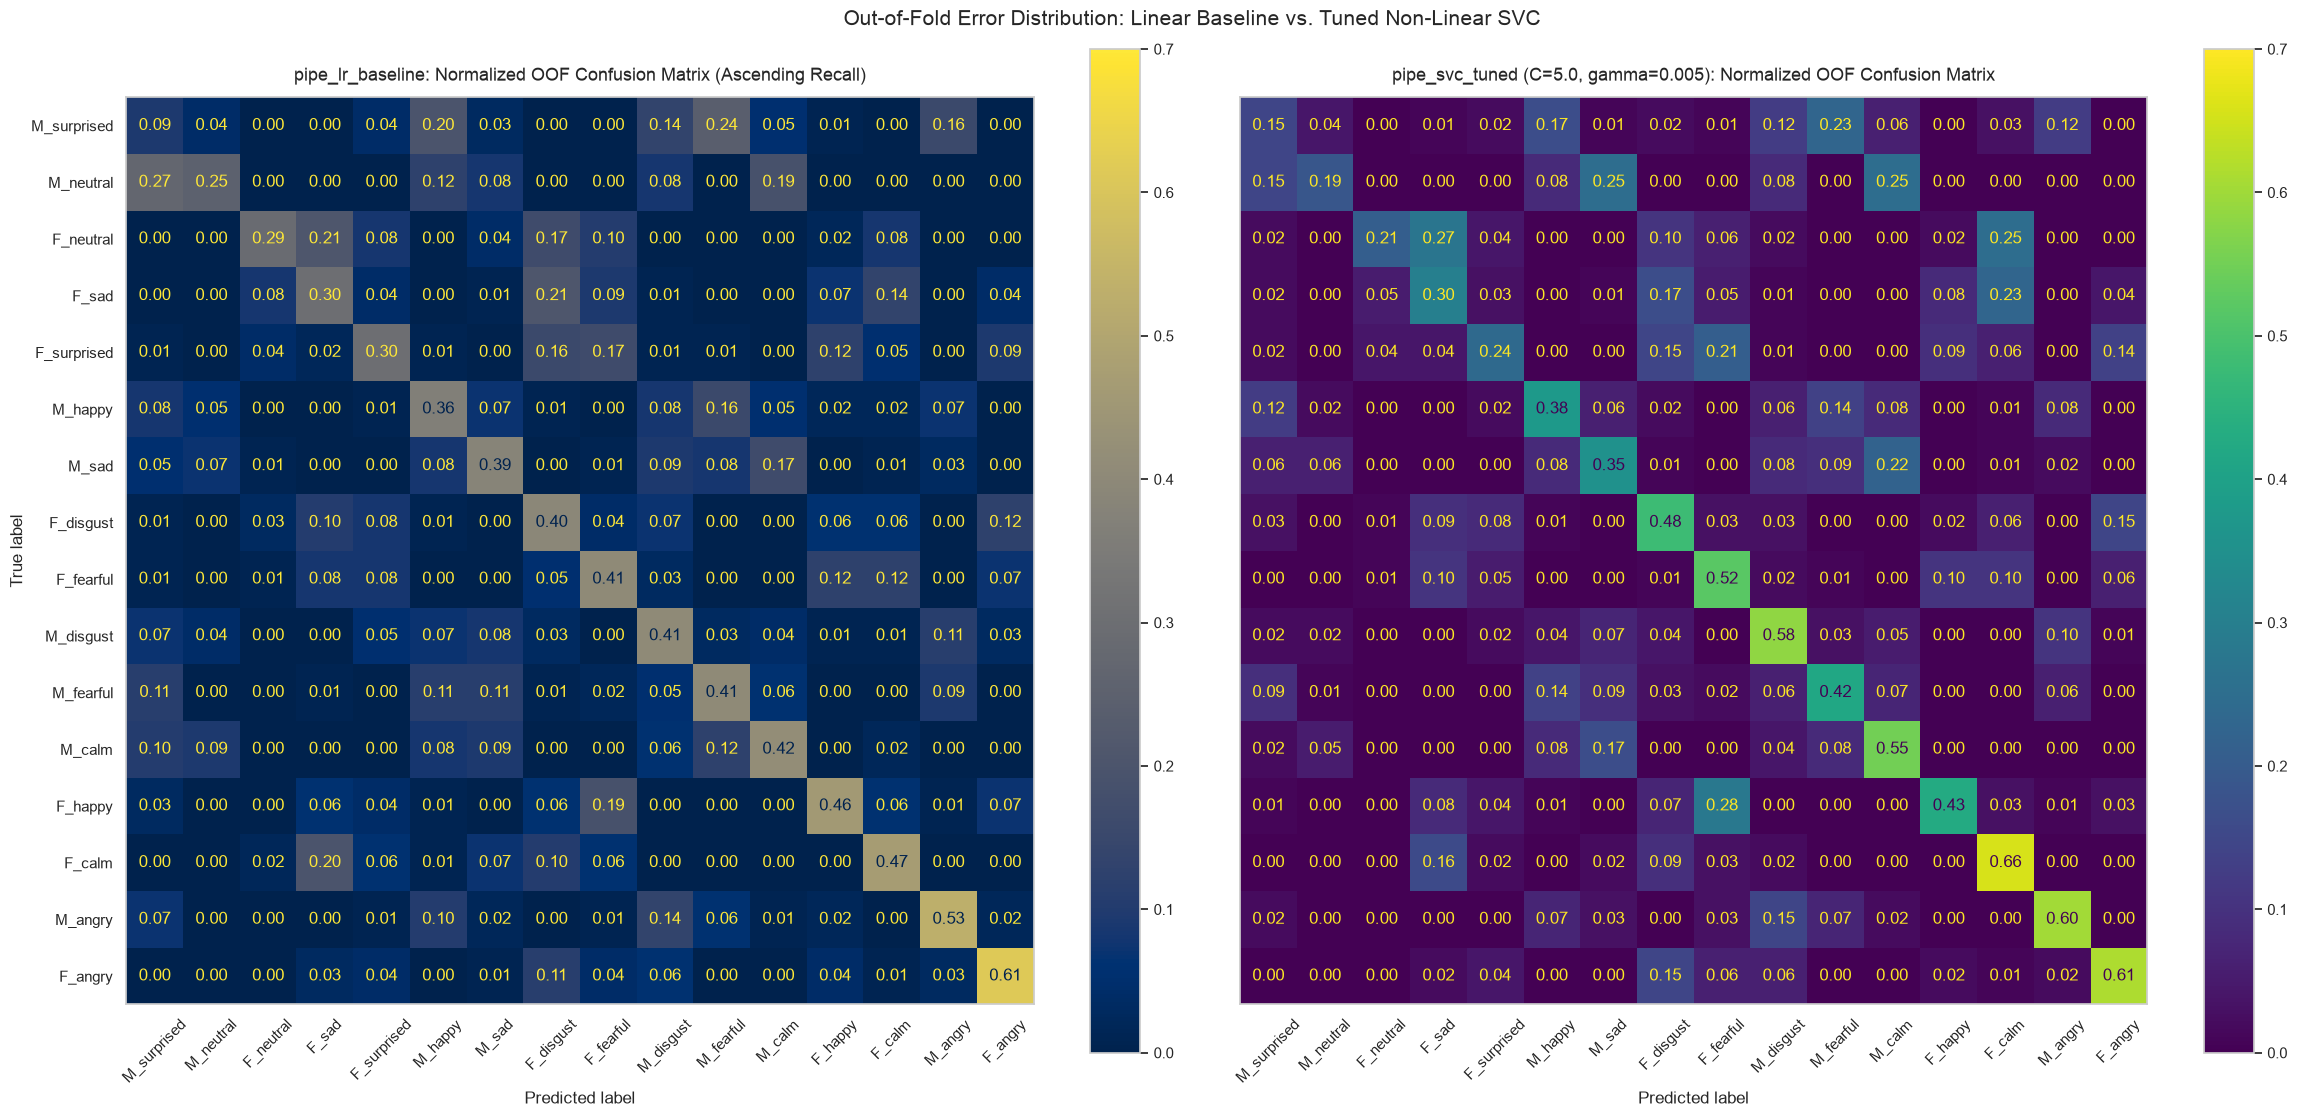

In [45]:
# side-by-side heatmap with baseline by reloading

# Extract the exact label sequence from the baseline image (ascending baseline recall)
labels_baseline_asc = [
    "M_surprised", "M_neutral", "F_neutral", "F_sad", 
    "F_surprised", "M_happy", "M_sad", "F_disgust", 
    "F_fearful", "M_disgust", "M_fearful", "M_calm", 
    "F_happy", "F_calm", "M_angry", "F_angry"
]

# Compute row-normalized confusion matrices under the identical baseline ordering
cm_lr_sync = confusion_matrix(
    y_vec,
    y_pred_oof_lr,
    labels=labels_baseline_asc,
    normalize="true",
)
cm_svc_sync = confusion_matrix(
    y_vec,
    y_pred_oof_tuned,
    labels=labels_baseline_asc,
    normalize="true",
)

# Plot side-by-side with synchronized axes and distinct colormaps
fig, axes = plt.subplots(1, 2, figsize=(24, 11), sharey=True)

# 1. Baseline: Exact original 'cividis' colormap
disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr_sync,
    display_labels=labels_baseline_asc,
)
disp_lr.plot(
    ax=axes[0],
    cmap="cividis",
    xticks_rotation=45,
    values_format=".2f",
    colorbar=True,
    im_kw={"vmin": 0.0, "vmax": 0.70},
)
axes[0].set_title(
    "pipe_lr_baseline: Normalized OOF Confusion Matrix (Ascending Recall)",
    fontsize=13,
    pad=12,
)
axes[0].grid(False)

# 2. Tuned SVC: New distinct colormap ('viridis')
disp_svc = ConfusionMatrixDisplay(
    confusion_matrix=cm_svc_sync,
    display_labels=labels_baseline_asc,
)
disp_svc.plot(
    ax=axes[1],
    cmap="viridis",
    xticks_rotation=45,
    values_format=".2f",
    colorbar=True,
    im_kw={"vmin": 0.0, "vmax": 0.70},
)
axes[1].set_title(
    "pipe_svc_tuned (C=5.0, gamma=0.005): Normalized OOF Confusion Matrix",
    fontsize=13,
    pad=12,
)
axes[1].set_ylabel("")  # Drop redundant y-axis label
axes[1].grid(False)

plt.suptitle(
    "Out-of-Fold Error Distribution: Linear Baseline vs. Tuned Non-Linear SVC",
    fontsize=15,
    y=0.98,
)
plt.tight_layout()
plt.show()

#### Tuned RBF SVC Standalone Performance
The tuned RBF Support Vector Classifier (`C=5.0`, `gamma=0.005`) achieved an overall out-of-fold accuracy of **43.13%** and a macro-averaged F1-score of **0.4110** across the 16 gender-emotion targets.

* The model demonstrates strongest reliability on classes defined by acoustic salience. Both female and male expressions of anger lead overall performance (`F_angry` F1: **0.6020**, `M_angry` F1: **0.5949**), followed closely by low-energy, steady-state expressions (`F_calm` F1: **0.5625**, `M_calm` F1: **0.5048**) and harsh timbral characteristics (`M_disgust` F1: **0.5045**).
* Neutral expressions suffer from weak recall (`F_neutral`: **20.83%**, `M_neutral`: **18.75%**), driven by confusion with neighboring subdued states (`F_sad` and `F_calm`). 
* Similarly, surprised expressions drop to the model floor (`M_surprised` F1: **0.1761**, recall: **14.58%**), where high-variance pitch bursts are frequently misattributed to other excited classes such as `M_fearful` and `M_happy`.

This is quite similar to the issues LR faced as well. How did the two of them comapre against each other?

---

#### Performance H2H: Tuned RBF SVC vs. Baseline
Contrasting the non-linear RBF SVC against the linear Logistic Regression baseline reveals both where kernel warping extracted genuine signal and where tabular MFCC summary statistics reach an architectural ceiling:

**Solid Lift in Targeted Acoustic Clusters:**
  * The non-linear kernel significantly tightened decision boundaries for low-energy speech, boosting `F_calm` recall from **0.47** to **0.66** and `M_calm` from **0.42** to **0.55**.
  * **Arousal Salience:** Notable improvements emerged across high-energy classes, with `M_disgust` recall advancing from **0.41** to **0.58** (`+17%`), `F_fearful` rising from **0.41** to **0.52** (`+11%`), and `M_angry` climbing from **0.53** to **0.60** (`+7%`).

**Persistent Intra-Gender Valence Confusion:**
  * While binary gender separation is near-perfect in both models (errors $< 5\%$) (see next section), separating positive vs. negative valence at equal arousal levels remains largely unresolved[cite: 4]. For instance, `F_happy` recall slipped from **0.46** to **0.43**, with **28%** of actual female happy trials misclassified as `F_fearful`
  * Similarly, the linear baseline's difficulty distinguishing flat neutral speech from sadness or calm persists in the SVC; `F_neutral` trials are misclassified into `F_sad` (**27%**) and `F_calm` (**25%**) at rates higher than its true class recall (**21%**).

Let's confirm the gender split identification.

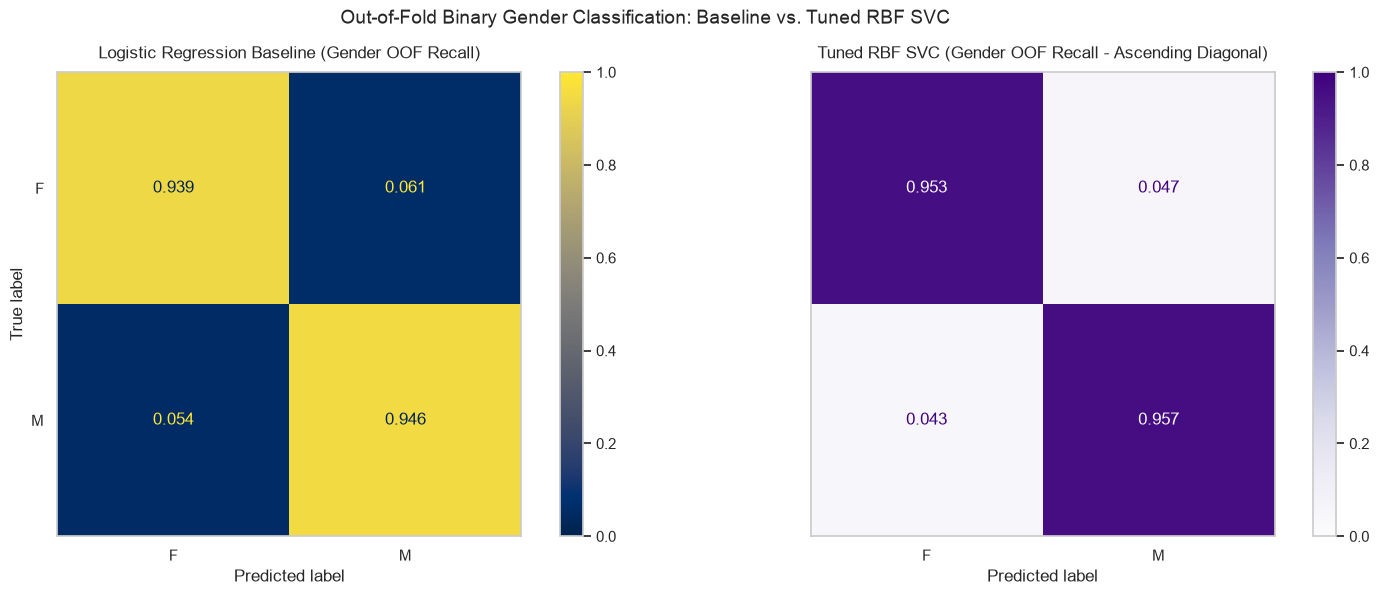

In [50]:
# Extract binary gender labels from compound target vector
y_gender_true = y_vec.str.split("_").str[0]
y_gender_pred_lr = pd.Series(y_pred_oof_lr, index=y_vec.index).str.split("_").str[0]
y_gender_pred_svc = pd.Series(y_pred_oof_tuned, index=y_vec.index).str.split("_").str[0]

# Determine label ordering strictly by ascending diagonal recall of tuned SVC
labels_gender_base = ["F", "M"]
cm_svc_temp = confusion_matrix(
    y_gender_true,
    y_gender_pred_svc,
    labels=labels_gender_base,
    normalize="true",
)
order_asc = np.argsort(np.diag(cm_svc_temp))
gender_labels_asc = [labels_gender_base[i] for i in order_asc]

# Compute row-normalized confusion matrices under identical ascending ordering
cm_gender_lr = confusion_matrix(
    y_gender_true,
    y_gender_pred_lr,
    labels=gender_labels_asc,
    normalize="true",
)
cm_gender_svc = confusion_matrix(
    y_gender_true,
    y_gender_pred_svc,
    labels=gender_labels_asc,
    normalize="true",
)

# Plot side-by-side comparison: Baseline (cividis) vs. Tuned SVC (Purples)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

#  Regenerate the LR confusion matrix with its original color scheme ('cividis')
disp_gender_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_gender_lr,
    display_labels=gender_labels_asc,
)
disp_gender_lr.plot(
    ax=axes[0],
    cmap="cividis",
    values_format=".3f",
    colorbar=True,
    im_kw={"vmin": 0.0, "vmax": 1.0},
)
axes[0].set_title(
    "Logistic Regression Baseline (Gender OOF Recall)",
    fontsize=12,
    pad=10,
)
axes[0].grid(False)

# 2. Tuned RBF SVC Gender Matrix using Purple palette ('Purples')
disp_gender_svc = ConfusionMatrixDisplay(
    confusion_matrix=cm_gender_svc,
    display_labels=gender_labels_asc,
)
disp_gender_svc.plot(
    ax=axes[1],
    cmap="Purples",
    values_format=".3f",
    colorbar=True,
    im_kw={"vmin": 0.0, "vmax": 1.0},
)
axes[1].set_title(
    "Tuned RBF SVC (Gender OOF Recall - Ascending Diagonal)",
    fontsize=12,
    pad=10,
)
axes[1].set_ylabel("")
axes[1].grid(False)

plt.suptitle(
    "Out-of-Fold Binary Gender Classification: Baseline vs. Tuned RBF SVC",
    fontsize=14,
    y=0.98,
)
plt.tight_layout()
plt.show()

acc_gender_svc = accuracy_score(y_gender_true, y_gender_pred_svc)
f1_gender_svc = f1_score(y_gender_true, y_gender_pred_svc, average="macro")

We can see that the tuned SVC improved on the gender identification performance as well, now achieveing a lower than **`5`%** error rate. The decision to revert back to a single model compound target variable is further vindicated here.

## Conclusion

* The transition from linear hyperplanes to an RBF kernel provided a measurable lift in overall accuracy (from **38.67%** to **43.13%**), successfully carving boundaries around acoustic extremes.
* However, compressing continuous audio into static mean and standard deviation summary statistics discards the time-varying pitch contours and formant trajectories necessary to decouple valence confusions (such as `happy` vs. `fearful` or `calm` vs. `sad`)
* We can attempt to resolve this by moving to 2D Log-Mel spectrograms modeled with spatial-temporal **convolutional networks**

In [51]:
# Save best SVC model and associated artifacts

# Resolve path to diagnostic evaluation artifact matching the 03_1 prefix
eval_artifact_path = models_dir / "03_1_svc_evaluation_bundle.joblib"

# Consolidate prediction arrays, metrics, and precomputed matrices
evaluation_bundle = {
    "labels_sync": labels_baseline_asc,
    "gender_labels_asc": gender_labels_asc,
    # Predictions
    "y_true": y_vec.to_numpy(),
    "y_pred_oof_lr": np.asarray(y_pred_oof_lr),
    "y_pred_oof_svc": np.asarray(y_pred_oof_tuned),
    "y_gender_true": y_gender_true.to_numpy(),
    "y_gender_pred_lr": y_gender_pred_lr.to_numpy(),
    "y_gender_pred_svc": y_gender_pred_svc.to_numpy(),
    # Precomputed Normalized Confusion Matrices
    "cm_lr_emotion": cm_lr_sync,
    "cm_svc_emotion": cm_svc_sync,
    "cm_gender_lr": cm_gender_lr,
    "cm_gender_svc": cm_gender_svc,
    # Summary Metrics
    "metrics_svc": {
        "accuracy": 0.4313,
        "macro_f1": 0.4110,
        "gender_accuracy": float(acc_gender_svc),
        "gender_f1": float(f1_gender_svc),
    },
}

# Serialize diagnostic bundle
joblib.dump(evaluation_bundle, eval_artifact_path)
print(f"Plot & evaluation bundle successfully saved to: {eval_artifact_path}")

Plot & evaluation bundle successfully saved to: /Users/abhisheknigam/workspace/github/my-ai/speech-emotion-router/data/processed/models/03_1_svc_evaluation_bundle.joblib


In [ ]:
# # Uncomment to load all phase 3 artifacts - model and metrics

# # Resolve paths to saved artifacts
# project_root = Path.cwd().resolve().parent
# models_dir = project_root / "data" / "processed" / "models"

# baseline_path = models_dir / "02_2_baseline_pipelines.joblib"
# svc_pipeline_path = models_dir / "03_1_svc_tuned_pipeline.joblib"
# svc_eval_path = models_dir / "03_1_svc_evaluation_bundle.joblib"

# # Load serialized bundles
# baseline_artifacts = joblib.load(baseline_path)
# svc_pipeline_artifacts = joblib.load(svc_pipeline_path)
# svc_eval_artifacts = joblib.load(svc_eval_path)

# # Extract baseline models and predictions
# pipe_dummy = baseline_artifacts["pipe_dummy_baseline"]
# pipe_lr = baseline_artifacts["pipe_lr_baseline"]
# y_pred_oof_lr = baseline_artifacts["y_pred_oof_lr"]
# baseline_labels = baseline_artifacts["labels"]

# # Extract tuned SVC pipeline and training metadata
# pipe_svc_tuned = svc_pipeline_artifacts["pipe_svc_tuned"]
# svc_best_params = svc_pipeline_artifacts["best_params"]
# svc_cv_results = svc_pipeline_artifacts["cv_results"]

# # Extract out-of-fold predictions, matrices, and metrics
# y_true = svc_eval_artifacts["y_true"]
# y_pred_oof_svc = svc_eval_artifacts["y_pred_oof_svc"]
# y_gender_true = svc_eval_artifacts["y_gender_true"]
# y_gender_pred_lr = svc_eval_artifacts["y_gender_pred_lr"]
# y_gender_pred_svc = svc_eval_artifacts["y_gender_pred_svc"]

# labels_sync = svc_eval_artifacts["labels_sync"]
# gender_labels_asc = svc_eval_artifacts["gender_labels_asc"]
# cm_lr_emotion = svc_eval_artifacts["cm_lr_emotion"]
# cm_svc_emotion = svc_eval_artifacts["cm_svc_emotion"]
# cm_gender_lr = svc_eval_artifacts["cm_gender_lr"]
# cm_gender_svc = svc_eval_artifacts["cm_gender_svc"]
# metrics_svc = svc_eval_artifacts["metrics_svc"]

# # Verification output
# print("=== Phase 1 Artifacts Loaded Successfully ===")
# print(f"Loaded Files:")
# print(f"  - {baseline_path.name}")
# print(f"  - {svc_pipeline_path.name}")
# print(f"  - {svc_eval_path.name}")
# print("\nSummary Verification:")
# print(f"  - Baseline LR OOF Samples: {len(y_pred_oof_lr)}")
# print(f"  - Tuned SVC OOF Samples:   {len(y_pred_oof_svc)}")
# print(f"  - Tuned SVC Parameters:    {svc_best_params}")
# print(f"  - Tuned SVC Accuracy:      {metrics_svc['accuracy']:.4f}")
# print(f"  - Tuned SVC Macro F1:      {metrics_svc['macro_f1']:.4f}")
# print(f"  - Tuned SVC Gender Acc:    {metrics_svc['gender_accuracy']:.4f}")